<a href="https://colab.research.google.com/github/kfafa2018-ux/Computer-Vision/blob/main/OpenCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Implement the following a new Jupyter notebook:
Finding Contours in the Image
Creating Bounding box and circles for contours
 Convex Hull
Histogram Equalisation
Please refer this link learn and implement the given topics : https://docs.opencv.org/4.x/d7/da8/tutorial_table_of_content_imgproc.html
Use the Notebook 1 and Notebook 2 for reference.



--- PREPROCESSING STEP ---
1. Histogram Equalized Grayscale:


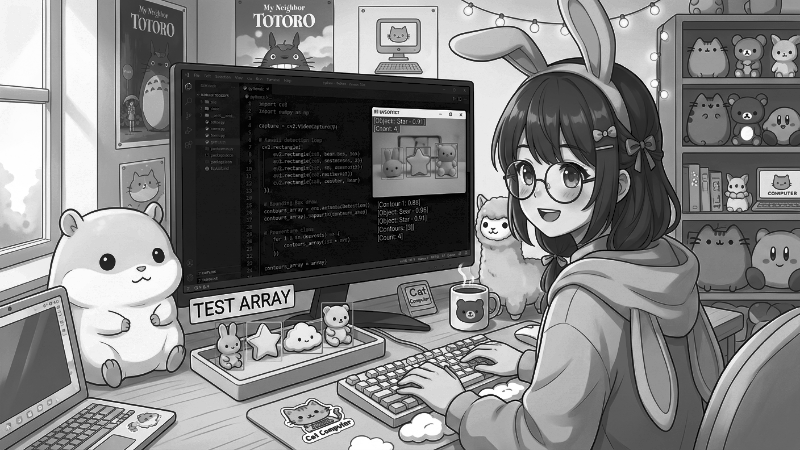


--- FINAL GEOMETRIC EXTRACTIONS ---
Green = Bounding Box | Blue = Enclosing Circle | Red = Convex Hull


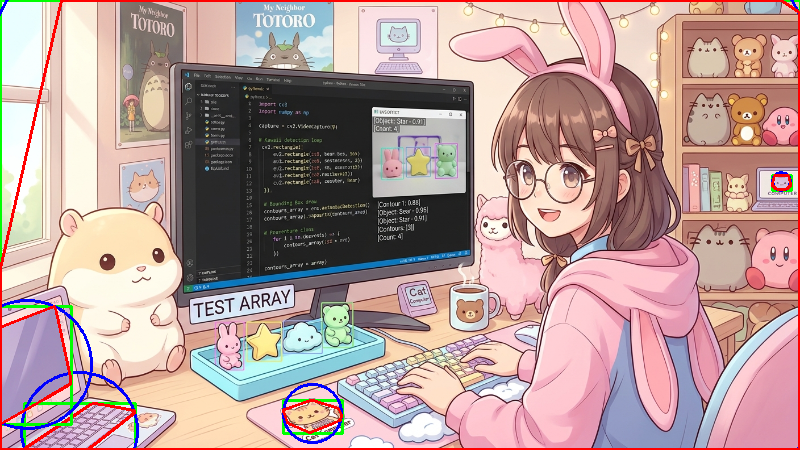

In [3]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow  # Change to cv2.imshow if running locally on your computer

# 1. Load the anime workspace image and convert to grayscale
img = cv2.imread('/content/drive/MyDrive/CV/Week 9/OneDrive_2026-10-19 (1)/Week 09 - Hands-On with OpenCV/Dependencies/Project Image.jpg')
img_resized = cv2.resize(img, (800, 450)) # Resizing for faster processing and display
gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

# ==========================================
# STEP 1: HISTOGRAM EQUALIZATION
# ==========================================
# Enhances the contrast of our grayscale image globally
equalized_gray = cv2.equalizeHist(gray)

# Binarize the image (turn to pure black & white) so we can find borders easily
_, thresh = cv2.threshold(equalized_gray, 127, 255, cv2.THRESH_BINARY_INV)

# ==========================================
# STEP 2: FINDING CONTOURS
# ==========================================
# Retrieves the structural boundaries from the binary image
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create copies of our image to draw our geometric outputs on
output_canvas = img_resized.copy()

# Loop through all detected contours to find their shapes
for i, cnt in enumerate(contours):
    # Ignore tiny background noise pixels (only look at actual objects)
    if cv2.contourArea(cnt) < 150:
        continue

    # ==========================================
    # STEP 3: CREATING BOUNDING BOXES & CIRCLES
    # ==========================================
    # A. Axis-Aligned Bounding Box (x, y coordinate origin, width, height)
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.rectangle(output_canvas, (x, y), (x + w, y + h), (0, 255, 0), 2) # GREEN Boxes

    # B. Minimum Enclosing Circle (center point coordinates, radius)
    (cx, cy), radius = cv2.minEnclosingCircle(cnt)
    center = (int(cx), int(cy))
    radius = int(radius)
    cv2.circle(output_canvas, center, radius, (255, 0, 0), 2) # BLUE Circles

    # ==========================================
    # STEP 4: CONVEX HULL
    # ==========================================
    # Finds the outermost envelope wrapping around the contour points
    hull = cv2.convexHull(cnt)
    cv2.drawContours(output_canvas, [hull], -1, (0, 0, 255), 2) # RED Convex Hulls

# ==========================================
# STEP 5: VISUALIZE RESULTS
# ==========================================
print("--- PREPROCESSING STEP ---")
print("1. Histogram Equalized Grayscale:")
cv2_imshow(equalized_gray)

print("\n--- FINAL GEOMETRIC EXTRACTIONS ---")
print("Green = Bounding Box | Blue = Enclosing Circle | Red = Convex Hull")
cv2_imshow(output_canvas)


We are going to take one of those detected contours (like a plushie or object) and use Inverse Trigonometry (\(\arctan \)) to calculate its precise angular tilt. Then, we will use Python to plot exactly what is happening inside the math engine.

The Math: Finding a Contour's Orientation Angle

Every shape found by cv2.findContours has "Image Moments" (\(M\)). These moments represent the spatial distribution of the pixel mass.
1. Centroid (Center of Mass): Calculated as \(\bar{x} = \frac{M_{10}}{M_{00}}\), \(\bar{y} = \frac{M_{01}}{M_{00}}\).
2. Central Moments (\(\mu \)): Measure how pixels spread out around that center.
3. The Trigonometric Angle Formula: To find the primary axis of orientation (\(\theta \)), we calculate the Arctangent of the central moments:
\(\theta =\frac{1}{2}\arctan \left(\frac{2\mu _{11}}{\mu _{20}-\mu _{02}}\right)\)



Visualizing the Math Concepts

Below is a geometric breakdown plot showing exactly how computer vision treats your contour coordinates as a trigonometric problem to calculate the principle axis of rotation

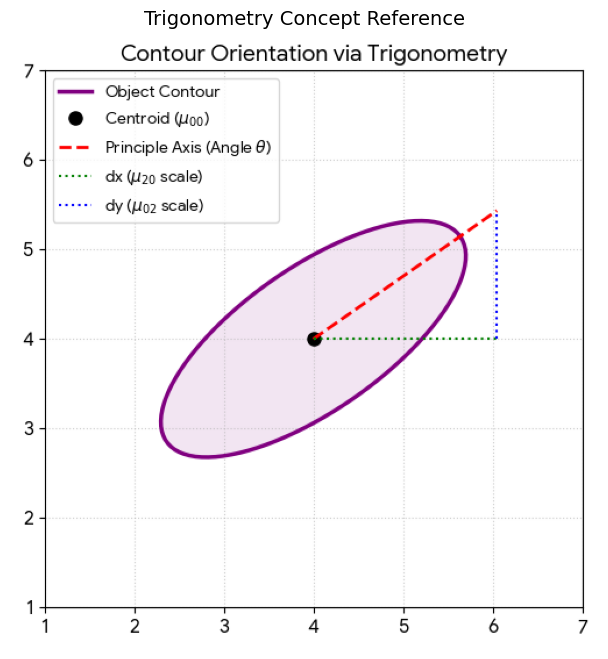

In [7]:
import cv2
import matplotlib.pyplot as plt

# Path to your trigonometry image
trig_image_path = '/content/drive/MyDrive/CV/Week 9/OneDrive_2026-10-19 (1)/Week 09 - Hands-On with OpenCV/Dependencies/graph.png'

# Read the image
trig_img = cv2.imread(trig_image_path)

if trig_img is not None:
    # Convert BGR (OpenCV) to RGB (Matplotlib)
    trig_img_rgb = cv2.cvtColor(trig_img, cv2.COLOR_BGR2RGB)

    # Display using matplotlib
    plt.figure(figsize=(10, 8))
    plt.imshow(trig_img_rgb)
    plt.axis('off')  # Hide grid lines and axes
    plt.title('Trigonometry Concept Reference', fontsize=14)
    plt.show()
else:
    print(f"Could not load the image at: {trig_image_path}. Please check if the file exists.")


Python Script: Tracking and Drawing Orientation Vectors

This script calculates the center and the exact angle of orientation for every object found in your anime image using trigonometry. It then prints out the angles and draws a red axis line directly down the "spine" of each shape.


--- Calculating Contour Orientations via Inverse Trig ---
Object 46 Found at Center (83, 426) | Tilt Angle: -21.99°
Object 47 Found at Center (311, 415) | Tilt Angle: 1.67°
Object 60 Found at Center (33, 363) | Tilt Angle: -71.92°
Object 164 Found at Center (442, 229) | Tilt Angle: 2.62°

Final Image with Vector Overlays (Red lines = calculated theta axis):


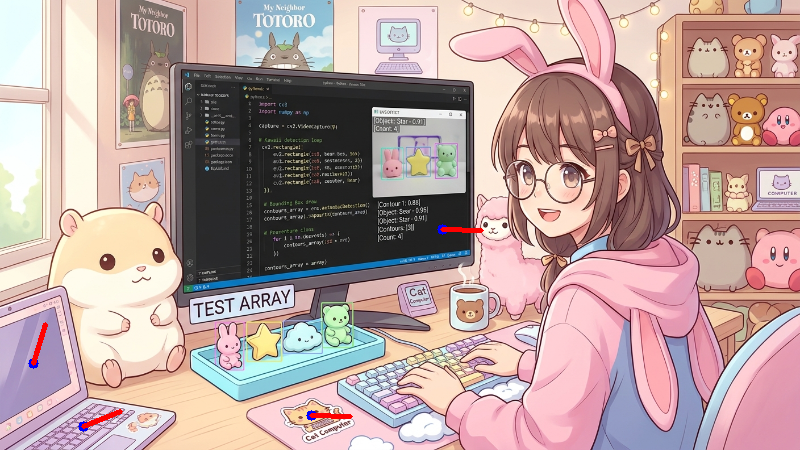

In [6]:
import cv2
import numpy as np
import math
from google.colab.patches import cv2_imshow # Change to cv2.imshow if running locally

# 1. Load and process image to get contours (from previous step)
img = cv2.imread('/content/drive/MyDrive/CV/Week 9/OneDrive_2026-10-19 (1)/Week 09 - Hands-On with OpenCV/Dependencies/Project Image.jpg')
img_resized = cv2.resize(img, (800, 450))
gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
equalized = cv2.equalizeHist(gray)
_, thresh = cv2.threshold(equalized, 127, 255, cv2.THRESH_BINARY_INV)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

output_img = img_resized.copy()

print("--- Calculating Contour Orientations via Inverse Trig ---")

for i, cnt in enumerate(contours):
    if cv2.contourArea(cnt) < 500: # Only analyze prominent objects
        continue

    # Calculate Moments of the contour
    M = cv2.moments(cnt)

    # Avoid dividing by zero if the contour has no area
    if M["m00"] == 0:
        continue

    # Calculate Centroid coordinates
    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])

    # Extract Central Moments
    mu11 = M["mu11"]
    mu20 = M["mu20"]
    mu02 = M["mu02"]

    # TRIGONOMETRY CORE: Calculate the orientation angle using math.atan2
    # This directly evaluates our 0.5 * arctan(2*mu11 / (mu20 - mu02)) relationship
    angle_rad = 0.5 * math.atan2(2 * mu11, mu20 - mu02)
    angle_deg = math.degrees(angle_rad)

    print(f"Object {i} Found at Center ({cx}, {cy}) | Tilt Angle: {angle_deg:.2f}°")

    # Use Sine and Cosine to draw a vector line showing the angle orientation
    line_length = 40
    # x = cx + length * cos(theta)
    # y = cy + length * sin(theta)
    endpoint_x = int(cx + line_length * math.cos(angle_rad))
    endpoint_y = int(cy + line_length * math.sin(angle_rad))

    # Draw a dot at the center of mass
    cv2.circle(output_img, (cx, cy), 5, (255, 0, 0), -1)

    # Draw the calculated trigonometric heading vector line
    cv2.line(output_img, (cx, cy), (endpoint_x, endpoint_y), (0, 0, 255), 3)

# Display the final math vector overlay
print("\nFinal Image with Vector Overlays (Red lines = calculated theta axis):")
cv2_imshow(output_img)